In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

In [5]:
df = pd.read_csv("smartcart_customers.csv")
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


In [6]:
df.shape

(2240, 22)

In [7]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

Data preprocessing

In [8]:
df["Income"]=df["Income"].fillna(df["Income"].median())
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


# Feature Engineering

In [9]:
df["Age"]=2026-df["Year_Birth"]
# customer joining date
df["Dt_Customer"]=pd.to_datetime(df["Dt_Customer"], dayfirst=True)
reference_date= df["Dt_Customer"].max()

df["Customer_Tenure_Days"]=(reference_date - df["Dt_Customer"]).dt.days


In [10]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'Customer_Tenure_Days'],
      dtype='object')

In [11]:
df["Total_Spending"]= df["MntWines"] + df["MntFruits"] +df["MntMeatProducts"] +df["MntFishProducts"] +df["MntSweetProducts"] +df["MntGoldProds"]
df["Total_Children"]= df["Teenhome"] + df["Kidhome"]

In [12]:
# undergraduate, graduate, postgraduate
df["Education"] = df["Education"].replace({
    "Basic": "Undergraduate", "2n Cycle": "Undergraduate",
    "Graduation": "Graduate",
    "Master": "Postgraduate", "PhD": "Postgraduate"
})
    

In [13]:
df["Education"].value_counts()

Education
Graduate         1127
Postgraduate      856
Undergraduate     257
Name: count, dtype: int64

In [14]:
# marital status
df["Living_With"]=df["Marital_Status"].replace({
    "Married": "Partner", "Together": "Undergraduate",
    "Single": "Alone", "Divorced": "Alone",
    "Widow": "Alone", "Absurd": "Alone", "YOLO": "Alone"
})

Drop Columns

In [15]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'Customer_Tenure_Days', 'Total_Spending',
       'Total_Children', 'Living_With'],
      dtype='object')

In [16]:
cols=["ID", "Year_Birth","Marital_Status", "Kidhome", "Teenhome" , "Dt_Customer"]
spending_cols=["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts" , "MntSweetProducts" , "MntGoldProds"]

cols_to_drop = cols + spending_cols
df_cleaned = df.drop(columns=cols_to_drop)

# Analyzing outliers

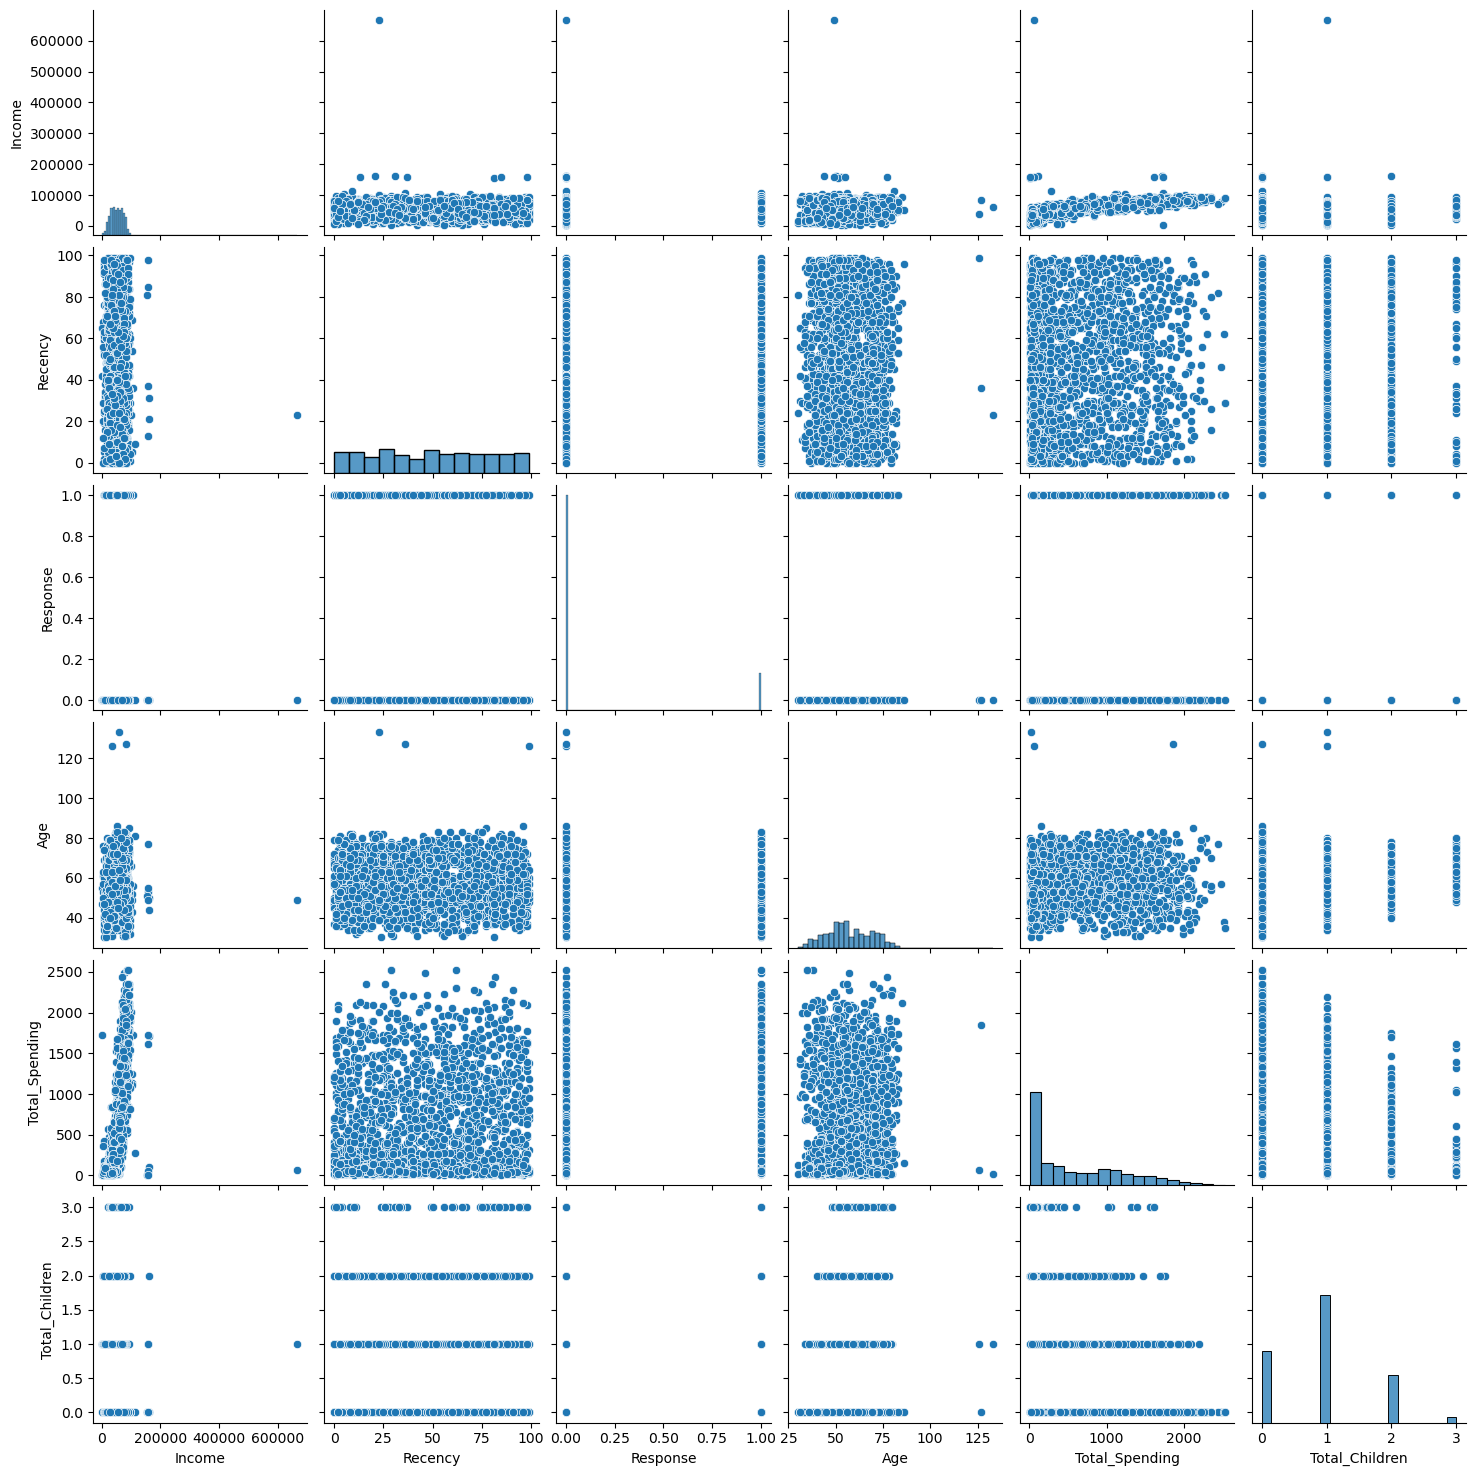

In [17]:
cols=["Income", "Recency", "Response", "Age", "Total_Spending", "Total_Children"]
sns.pairplot(df_cleaned[cols])

In [18]:
# remove outliers

print("with outlier :- ",len(df_cleaned))

df_cleaned = df_cleaned[(df_cleaned["Age"]<90)]
df_cleaned = df_cleaned[(df_cleaned["Income"]< 600_000)]

print("without outlier :- ",len(df_cleaned))



with outlier :-  2240
without outlier :-  2236


<Axes: >

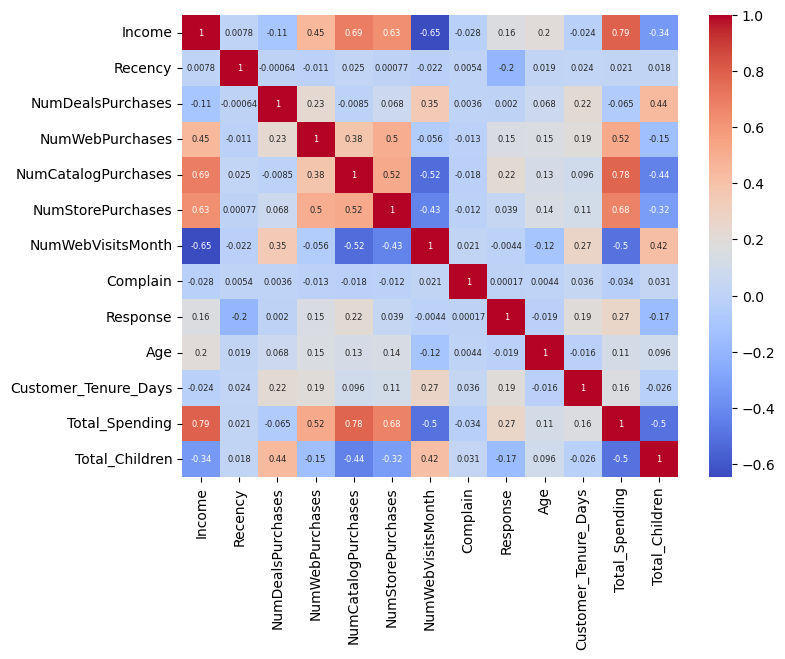

In [19]:
# checking correlation
corr=df_cleaned.corr(numeric_only=True)
plt.figure(figsize=(8,6))
sns.heatmap(
    corr,
    annot=True,
    annot_kws={"size":6},
    cmap="coolwarm"
)

In [20]:
from sklearn.preprocessing import OneHotEncoder
ohe= OneHotEncoder()
cat_cols = ["Education", "Living_With"]
enc_cols= ohe.fit_transform(df_cleaned[cat_cols])
enc_df=pd.DataFrame(enc_cols.toarray(), columns=ohe.get_feature_names_out(cat_cols), index=df_cleaned.index)
df_encoded = pd.concat([df_cleaned.drop(columns=cat_cols),enc_df],axis=1)

In [21]:
from sklearn.preprocessing import StandardScaler
X=df_encoded
scaler=StandardScaler()
x_scaled= scaler.fit_transform(X)

visualize

In [22]:
from sklearn.decomposition import PCA

In [23]:
pca=PCA(n_components=3)
x_pca=pca.fit_transform(x_scaled)

In [24]:
pca.explained_variance_ratio_

array([0.2194088 , 0.09865268, 0.09395884])

Text(0.5, 0.92, '3 d visualization of PCA components')

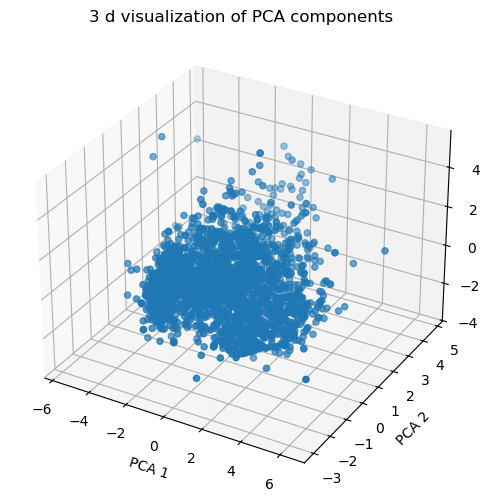

In [25]:
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111,projection="3d")
ax.scatter(x_pca[:,0],x_pca[:,1],x_pca[:,2])
ax.set_xlabel("PCA 1")
ax.set_ylabel("PCA 2")
ax.set_zlabel("PCA 3")
ax.set_title("3 d visualization of PCA components")

In [26]:
!pip install kneed

Defaulting to user installation because normal site-packages is not writeable


In [27]:
from sklearn.cluster import KMeans
from kneed import KneeLocator
wcss=[]
for k in range(1,11):
    kmeans=KMeans(n_clusters=k,random_state=42)
    kmeans.fit_transform(x_pca)
    wcss.append(kmeans.inertia_)
    

In [29]:
knee = KneeLocator(range(1,11),wcss, curve="convex",direction="decreasing")
optimal_k= knee.elbow
print("best k value :- ",optimal_k)

best k value :-  3


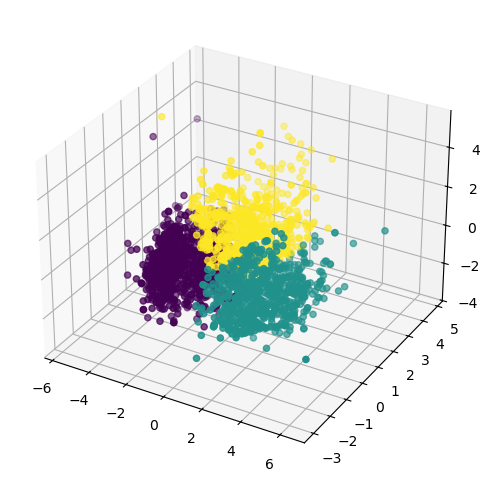

In [30]:
# applying knn
kmeans=KMeans(n_clusters=3, random_state=42)
labels_kmeans=kmeans.fit_predict(x_pca)
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111,projection="3d")
ax.scatter(x_pca[:,0],x_pca[:,1],x_pca[:,2],c=labels_kmeans)

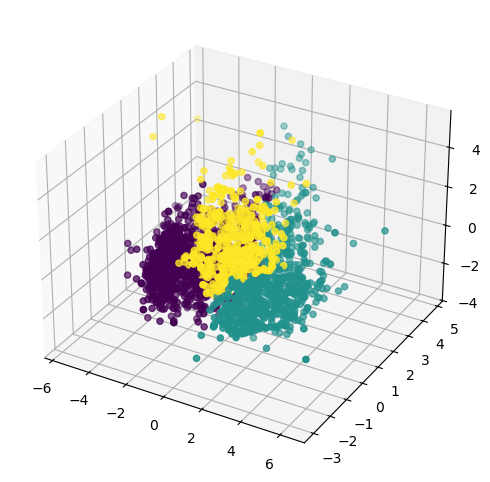

In [31]:
# applying agglomerative
from sklearn.cluster import AgglomerativeClustering
agg_clf=AgglomerativeClustering(n_clusters=3,linkage="ward")
labels_agg=agg_clf.fit_predict(x_pca)
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111,projection="3d")
ax.scatter(x_pca[:,0],x_pca[:,1],x_pca[:,2],c=labels_agg)

In [42]:
X.columns

Index(['Income', 'Recency', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'Customer_Tenure_Days', 'Total_Spending',
       'Total_Children', 'Education_Graduate', 'Education_Postgraduate',
       'Education_Undergraduate', 'Living_With_Alone', 'Living_With_Partner',
       'Living_With_Undergraduate'],
      dtype='object')

<Axes: xlabel='cluster', ylabel='count'>

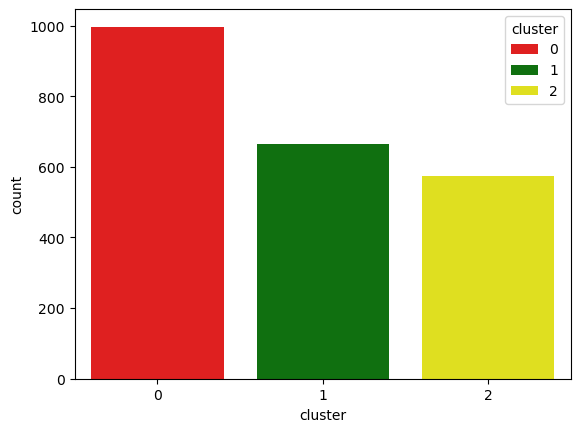

In [43]:
# characterization of clusters

X["cluster"]=labels_kmeans
pal=["red","green","yellow"]
sns.countplot(x=X["cluster"],palette=pal, hue=X["cluster"])

<Axes: xlabel='Total_Spending', ylabel='Income'>

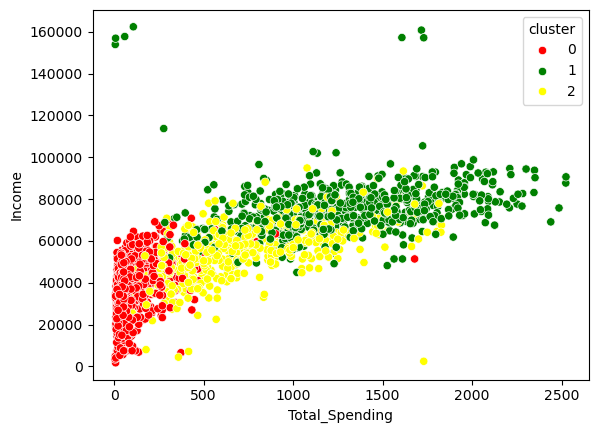

In [44]:
sns.scatterplot(x=X["Total_Spending"],y=X["Income"],hue=X["cluster"],palette=pal)

In [45]:
# cluster summary
cluster_summary=X.groupby("cluster").mean()
print(cluster_summary)

               Income    Recency  NumDealsPurchases  NumWebPurchases  \
cluster                                                                
0        34643.683551  49.575727           1.900702         2.025075   
1        75429.834337  49.703313           1.293675         5.121988   
2        54853.708696  47.641739           4.255652         6.469565   

         NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
cluster                                                                        
0                   0.535607           3.228686           6.348044  0.011033   
1                   5.694277           8.450301           2.796687  0.006024   
2                   2.852174           7.180870           6.446957  0.008696   

         Response        Age  Customer_Tenure_Days  Total_Spending  \
cluster                                                              
0        0.068205  54.411234            305.594784       96.833501   
1        0.240964  58.304217